In [1]:
import pandas as pd

In [2]:
df = pd.read_csv(r"C:\Users\Benjamin\Documents\Online Retail.csv")

In [3]:
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


In [5]:
df.shape

(541909, 8)

In [6]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [7]:
df.duplicated().sum()

np.int64(5268)

In [8]:
duplicate_count = df.duplicated().sum()
duplicate_percentage = (duplicate_count / len(df)) * 100

print(f"Duplicate rows: {duplicate_count:,}")
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Duplicate rows: 5,268
Duplicate percentage: 0.97%


In [9]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [10]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [11]:
df[df["Quantity"] < 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,12/1/2010 10:24,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,12/1/2010 10:24,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,12/1/2010 12:38,4.25,17897.0,United Kingdom


In [12]:
df[df["Quantity"] < 0].shape[0]

10624

In [13]:
negative_quantity_count = (df["Quantity"] < 0).sum()

negative_quantity_percentage = (
    negative_quantity_count / len(df)
) * 100

print(f"Negative quantity records: {negative_quantity_count:,}")
print(f"Percentage of dataset: {negative_quantity_percentage:.2f}%")

Negative quantity records: 10,624
Percentage of dataset: 1.96%


In [14]:
negative_quantity_df = df[df["Quantity"] < 0]

cancelled_invoice_count = negative_quantity_df[
    negative_quantity_df["InvoiceNo"].str.startswith("C")
].shape[0]

print(f"Negative quantity records: {len(negative_quantity_df):,}")
print(f"Records with cancellation invoices: {cancelled_invoice_count:,}")

Negative quantity records: 10,624
Records with cancellation invoices: 9,288


In [15]:
negative_quantity_df[
    ~negative_quantity_df["InvoiceNo"].str.startswith("C")
].head(10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,12/1/2010 16:50,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,12/2/2010 14:42,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,12/3/2010 15:30,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,12/3/2010 15:30,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,12/3/2010 15:30,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,12/3/2010 15:32,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,12/3/2010 15:33,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,12/3/2010 15:33,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,12/3/2010 15:34,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,12/3/2010 15:35,0.0,NaN,United Kingdom


In [16]:
negative_quantity_df[
    ~negative_quantity_df["InvoiceNo"].str.startswith("C")
].head(10).to_string()

'     InvoiceNo StockCode Description  Quantity      InvoiceDate  UnitPrice  CustomerID         Country\n2406    536589     21777         NaN       -10  12/1/2010 16:50        0.0         NaN  United Kingdom\n4347    536764    84952C         NaN       -38  12/2/2010 14:42        0.0         NaN  United Kingdom\n7188    536996     22712         NaN       -20  12/3/2010 15:30        0.0         NaN  United Kingdom\n7189    536997     22028         NaN       -20  12/3/2010 15:30        0.0         NaN  United Kingdom\n7190    536998     85067         NaN        -6  12/3/2010 15:30        0.0         NaN  United Kingdom\n7192    537000     21414         NaN       -22  12/3/2010 15:32        0.0         NaN  United Kingdom\n7193    537001     21653         NaN        -6  12/3/2010 15:33        0.0         NaN  United Kingdom\n7195    537003     85126         NaN        -2  12/3/2010 15:33        0.0         NaN  United Kingdom\n7196    537004     21814         NaN       -30  12/3/2010 15:34

In [17]:
negative_zero_price = df[
    (df["Quantity"] < 0) &
    (df["UnitPrice"] == 0)
]

print(f"Records with negative quantity and zero price: {len(negative_zero_price):,}")

Records with negative quantity and zero price: 1,336


In [18]:
negative_zero_price["Description"].isna().sum()

np.int64(862)

In [19]:
missing_description_count = negative_zero_price["Description"].isna().sum()

missing_description_percentage = (
    missing_description_count / len(negative_zero_price)
) * 100

print(f"Records with missing descriptions: {missing_description_count:,}")
print(f"Percentage of this group: {missing_description_percentage:.2f}%")

Records with missing descriptions: 862
Percentage of this group: 64.52%


In [20]:
df[df["UnitPrice"] < 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,8/12/2011 14:51,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,8/12/2011 14:52,-11062.06,NaN,United Kingdom


In [21]:
negative_price_count = (df["UnitPrice"] < 0).sum()

print(f"Records with negative unit prices: {negative_price_count:,}")

Records with negative unit prices: 2


In [22]:
(df["Quantity"] == 0).sum()

np.int64(0)

In [23]:
df["InvoiceDate"].dtype

<StringDtype(na_value=nan)>

In [24]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [25]:
df["InvoiceDate"].dtype

dtype('<M8[us]')

In [26]:
df["InvoiceDate"].head()

0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
Name: InvoiceDate, dtype: datetime64[us]

In [27]:
df["SalesValue"] = df["Quantity"] * df["UnitPrice"]

In [28]:
df[["Quantity", "UnitPrice", "SalesValue"]].head(10)

,Quantity,UnitPrice,SalesValue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34
5,2,7.65,15.30
6,6,4.25,25.50
7,6,1.85,11.10
8,6,1.85,11.10
9,32,1.69,54.08


In [29]:
df["SalesValue"].sum()

np.float64(9747747.934)

In [30]:
country_sales = (
    df.groupby("Country")["SalesValue"]
    .sum()
    .sort_values(ascending=False)
)

country_sales.head(10)

Country
United Kingdom    8187806.364
Netherlands        284661.540
EIRE               263276.820
Germany            221698.210
France             197403.900
Australia          137077.270
Switzerland         56385.350
Spain               54774.580
Belgium             40910.960
Sweden              36595.910
Name: SalesValue, dtype: float64

In [31]:
monthly_sales = (
    df.groupby(df["InvoiceDate"].dt.to_period("M"))["SalesValue"]
    .sum()
)

monthly_sales

InvoiceDate
2010-12     748957.020
2011-01     560000.260
2011-02     498062.650
2011-03     683267.080
2011-04     493207.121
2011-05     723333.510
2011-06     691123.120
2011-07     681300.111
2011-08     682680.510
2011-09    1019687.622
2011-10    1070704.670
2011-11    1461756.250
2011-12     433668.010
Freq: M, Name: SalesValue, dtype: float64

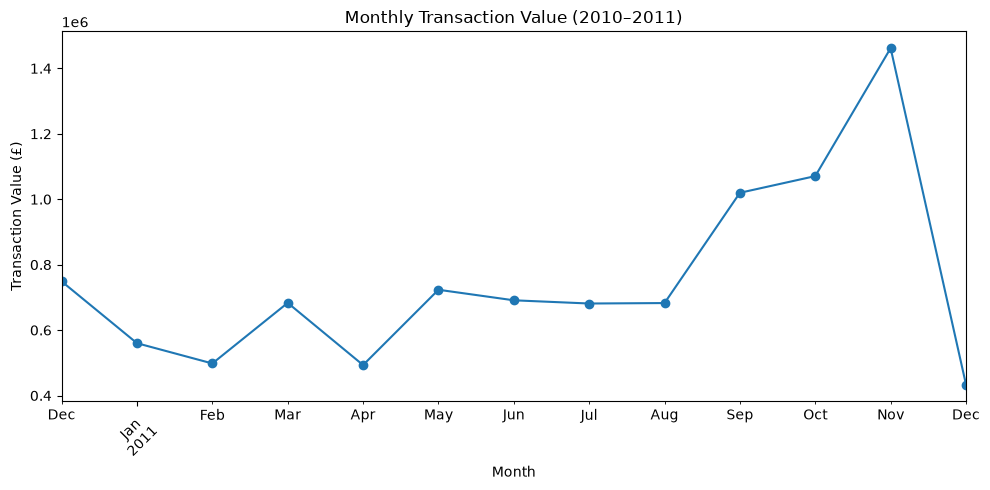

In [32]:
import matplotlib.pyplot as plt

monthly_sales.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Monthly Transaction Value (2010–2011)")
plt.xlabel("Month")
plt.ylabel("Transaction Value (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [33]:
df["InvoiceDate"].dtype

dtype('<M8[us]')

In [34]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [35]:
df["InvoiceDate"].dtype

dtype('<M8[us]')

In [36]:
monthly_sales = (
    df.groupby(df["InvoiceDate"].dt.to_period("M"))["SalesValue"]
    .sum()
)

monthly_sales

InvoiceDate
2010-12     748957.020
2011-01     560000.260
2011-02     498062.650
2011-03     683267.080
2011-04     493207.121
2011-05     723333.510
2011-06     691123.120
2011-07     681300.111
2011-08     682680.510
2011-09    1019687.622
2011-10    1070704.670
2011-11    1461756.250
2011-12     433668.010
Freq: M, Name: SalesValue, dtype: float64

In [37]:
highest_month = monthly_sales.idxmax()
highest_value = monthly_sales.max()

print(f"Highest month: {highest_month}")
print(f"Transaction value: £{highest_value:,.2f}")

Highest month: 2011-11
Transaction value: £1,461,756.25


In [38]:
october_sales = monthly_sales.loc["2011-10"]
november_sales = monthly_sales.loc["2011-11"]

increase = november_sales - october_sales

print(f"Increase: £{increase:,.2f}")

Increase: £391,051.58


In [39]:
percentage_increase = (increase / october_sales) * 100

print(f"Percentage increase: {percentage_increase:.2f}%")

Percentage increase: 36.52%


In [40]:
negative_qty = df[df['Quantity'] < 0]
len(negative_qty)

10624

In [41]:
df['InvoiceNo'].astype(str).str.startswith('C')

0         False
1         False
2         False
3         False
4         False
          ...  
541904    False
541905    False
541906    False
541907    False
541908    False
Name: InvoiceNo, Length: 541909, dtype: bool

In [42]:
cancellations = df[df['InvoiceNo'].astype(str).str.startswith('C')]
len(cancellations)
type(cancellations)

pandas.DataFrame

In [43]:
is_cancel = df['InvoiceNo'].astype(str).str.startswith('C')
is_zero_price = (df['UnitPrice'] == 0) & (~is_cancel)

In [44]:
is_cancel.sum()


np.int64(9288)

In [45]:

is_zero_price.sum()

np.int64(2515)

In [46]:
cancellations = df[is_cancel]
zero_price_adjustments = df[is_zero_price]
normal_sales = df[~is_cancel & ~is_zero_price]

len(cancellations) + len(zero_price_adjustments) + len(normal_sales)

541909

In [47]:
 (df['UnitPrice'] == 0) & (is_cancel).sum()

0         False
1         False
2         False
3         False
4         False
          ...  
541904    False
541905    False
541906    False
541907    False
541908    False
Name: UnitPrice, Length: 541909, dtype: bool

In [48]:
((df['UnitPrice'] == 0) & (is_cancel)).sum()

np.int64(0)

In [49]:
zero_and_cancel = (df['UnitPrice'] == 0) & (is_cancel)
zero_and_cancel.sum()

np.int64(0)

In [50]:
zero_price_adjustments['Quantity'].describe()


count     2515.000000
mean       -53.421074
std        540.206783
min      -9600.000000
25%        -32.000000
50%         -1.000000
75%          3.000000
max      12540.000000
Name: Quantity, dtype: float64

In [51]:

zero_price_adjustments['Description'].isna().sum()

np.int64(1454)

In [52]:

(zero_price_adjustments['Quantity'] < 0).sum()

np.int64(1336)

In [53]:
(zero_price_adjustments['Quantity'] > 0).sum()


np.int64(1179)

Cancellations: 9,288 rows. Zero-price rows: 2,515 (1,336 negative, 1,179 positive, all 1,454 missing descriptions). Normal sales: the rest. Total: 541,909.

In [54]:
normal_sales['StockCode'].value_counts().head(20)

StockCode
85123A    2265
85099B    2112
22423     2017
47566     1706
20725     1595
84879     1489
22197     1426
22720     1399
21212     1370
20727     1328
22383     1326
22457     1263
23203     1249
22386     1238
22469     1226
22086     1200
21931     1197
22411     1190
22382     1179
20728     1174
Name: count, dtype: int64

In [55]:
non_product_codes = ['POST', 'D', 'M', 'DOT', 'BANK CHARGES', 'B', 'CRUK', 'C2', 'S', 'AMAZONFEE']
normal_sales['StockCode'].isin(non_product_codes).sum()

np.int64(2313)

In [56]:
non_product_rows = normal_sales[normal_sales['StockCode'].isin(non_product_codes)]
non_product_rows['StockCode'].value_counts()

StockCode
POST            1126
DOT              706
M                321
C2               141
BANK CHARGES      12
B                  3
AMAZONFEE          2
S                  2
Name: count, dtype: int64

In [57]:
# 1. Add SalesValue to normal_sales first
normal_sales = normal_sales.assign(SalesValue=normal_sales['Quantity'] * normal_sales['UnitPrice'])

# 2. THEN rebuild non_product_rows from the updated normal_sales
non_product_rows = normal_sales[normal_sales['StockCode'].isin(non_product_codes)]

# 3. Now the column exists
non_product_rows['SalesValue'].sum()

np.float64(372439.001)

In [58]:
non_product_rows['StockCode'].value_counts()

StockCode
POST            1126
DOT              706
M                321
C2               141
BANK CHARGES      12
B                  3
AMAZONFEE          2
S                  2
Name: count, dtype: int64

In [59]:
# 1. Value per code
non_product_rows.groupby('StockCode')['SalesValue'].sum().sort_values()

StockCode
B               -11062.060
S                   63.050
BANK CHARGES       165.001
C2                7051.000
AMAZONFEE        13761.090
POST             78101.880
M                78110.270
DOT             206248.770
Name: SalesValue, dtype: float64

In [60]:
# 2. Remove these rows from normal sales to get real product sales
product_sales = normal_sales[~normal_sales['StockCode'].isin(non_product_codes)]

# 3. Check the split, as you did before
len(product_sales) + len(non_product_rows) == len(normal_sales)

True

In [61]:
len(product_sales)

527793

In [62]:
product_sales['SalesValue'].sum()

np.float64(10272121.423)

In [63]:
cancellations['Quantity'].mul(cancellations['UnitPrice']).sum()

np.float64(-896812.49)

Group	Value
Product sales	£10,272,121.42
Cancellations	-£896,812.49
Non-product codes	£372,439.00
Zero-price rows	£0
Total	£9,747,747.93

In [64]:
product_sales.groupby('Description')['SalesValue'].sum().sort_values(ascending=False).head(10)

Description
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66964.99
PAPER CHAIN KIT 50'S CHRISTMAS         64952.29
ASSORTED COLOUR BIRD ORNAMENT          59094.93
CHILLI LIGHTS                          54117.76
Name: SalesValue, dtype: float64

In [65]:
product_sales[product_sales['Description'] == 'PAPER CRAFT , LITTLE BIRDIE'].sort_values('Quantity', ascending=False).head(3)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesValue
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,168469.6


In [66]:
cancellations[cancellations['Quantity'] == -80995]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesValue
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom,-168469.6


In [67]:
df[df['Description'] == 'PAPER CRAFT , LITTLE BIRDIE'].assign(SalesValue=df['Quantity'] * df['UnitPrice'])['SalesValue'].sum()

np.float64(0.0)

In [68]:
len(df[df['Description'] == 'PAPER CRAFT , LITTLE BIRDIE'])

2

In [69]:
net_by_product = df[~df['StockCode'].isin(non_product_codes)].assign(SalesValue=df['Quantity'] * df['UnitPrice']).groupby('Description')['SalesValue'].sum().sort_values(ascending=False).head(10)
net_by_product

Description
REGENCY CAKESTAND 3 TIER              164762.19
WHITE HANGING HEART T-LIGHT HOLDER     99668.47
PARTY BUNTING                          98302.98
JUMBO BAG RED RETROSPOT                92356.03
RABBIT NIGHT LIGHT                     66756.59
PAPER CHAIN KIT 50'S CHRISTMAS         63791.94
ASSORTED COLOUR BIRD ORNAMENT          58959.73
CHILLI LIGHTS                          53768.06
SPOTTY BUNTING                         42065.32
JUMBO BAG PINK POLKADOT                41619.66
Name: SalesValue, dtype: float64

In [70]:
df[df['Description'] == 'MEDIUM CERAMIC TOP STORAGE JAR'].assign(SalesValue=df['Quantity'] * df['UnitPrice'])['SalesValue'].sum()

np.float64(4221.280000000013)

In [71]:
cancellations[cancellations['Description'] == 'MEDIUM CERAMIC TOP STORAGE JAR'].sort_values('Quantity').head(3)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesValue
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom,-77183.6
234364,C557508,23166,MEDIUM CERAMIC TOP STORAGE JAR,-240,2011-06-20 16:13:00,1.04,16684.0,United Kingdom,-249.6
290357,C562375,23166,MEDIUM CERAMIC TOP STORAGE JAR,-12,2011-08-04 14:46:00,1.25,14911.0,EIRE,-15.0


In [72]:
df[df['CustomerID'] == 12346]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesValue
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom,77183.6
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom,-77183.6


In [73]:
product_sales[product_sales['InvoiceDate'].dt.to_period('M') == '2011-01']['SalesValue'].sum()

np.float64(671992.41)

In [74]:
df[~df['StockCode'].isin(non_product_codes)].assign(SalesValue=df['Quantity'] * df['UnitPrice']).pipe(lambda d: d[d['InvoiceDate'].dt.to_period('M') == '2011-01']['SalesValue'].sum())

np.float64(580466.1100000001)

In [75]:
net_sales = df[~df['StockCode'].isin(non_product_codes)].copy()
net_sales['SalesValue'] = net_sales['Quantity'] * net_sales['UnitPrice']
net_sales[net_sales['InvoiceDate'].dt.to_period('M') == '2011-01']['SalesValue'].sum()

np.float64(580466.1100000001)

In [76]:
monthly_net = net_sales.groupby(net_sales['InvoiceDate'].dt.to_period('M'))['SalesValue'].sum()
monthly_net

InvoiceDate
2010-12     760403.050
2011-01     580466.110
2011-02     500577.000
2011-03     680590.640
2011-04     482992.881
2011-05     732327.510
2011-06     725116.040
2011-07     677988.531
2011-08     702675.640
2011-09    1013455.681
2011-10    1062694.330
2011-11    1432734.990
2011-12     441374.840
Freq: M, Name: SalesValue, dtype: float64

## Transaction Groups

The 541,909 rows were split into four non-overlapping groups:

| Group | Rows | Notes |
|---|---|---|
| Cancellations (invoice starts with "C") | 9,288 | All have negative quantities |
| Zero-price rows (not cancellations) | 2,515 | 1,336 negative and 1,179 positive quantities; all 1,454 missing descriptions are in this group |
| Non-product codes (POST, DOT, M, C2, etc.) | 2,313 | Fees, postage and adjustments, not products |
| Product sales | 527,793 | |

The four groups add up to 541,909, so no row was lost or double-counted.
The zero-price rows may be stock adjustments, but this is a hypothesis and has not been confirmed.

## Reconciliation to the Original Total

| Group | Value (£) |
|---|---|
| Product sales | 10,272,121.42 |
| Cancellations | -896,812.49 |
| Non-product codes | 372,439.00 |
| Zero-price rows | 0 |
| **Total** | **9,747,747.93** |

This matches the original preliminary total, so every pound is explained.

## Finding: Two Large Orders Were Cancelled Within Minutes

- Invoice 581483 (80,995 units, £168,469.60) was cancelled 12 minutes later by invoice C581484.
- Invoice 541431 (74,215 units, £77,183.60) was cancelled 16 minutes later by invoice C541433 (customer 12346).

Each pair nets to £0. Because cancellations were stored separately, these sales stayed in the product-sales group and inflated rankings and monthly totals. For example, "PAPER CRAFT, LITTLE BIRDIE" ranked second by gross value but had a net value of £0.

**Decision:** rankings and monthly totals use net sales, where cancellations offset their sales.

## Effect of Using Net Sales

- Top product: REGENCY CAKESTAND 3 TIER, £164,762.19 net.
- MEDIUM CERAMIC TOP STORAGE JAR fell from £81,700.92 gross to £4,221.28 net, because of a 74,215-unit return.
- January 2011: £671,992.41 (product sales only) vs £580,466.11 (net). The same month changes depending on what is included.

The cancellation rate (about 8.7% of product sales value) is provisional, because the two phantom orders affect both the numerator and the denominator.

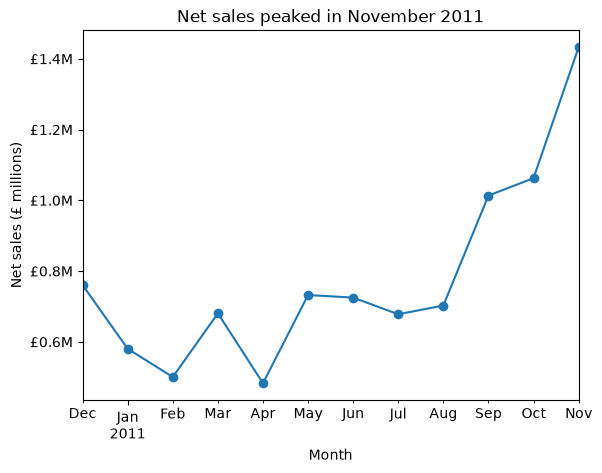

In [77]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

full_months = monthly_net.iloc[:-1]

ax = full_months.plot(kind='line', marker='o')
ax.set_title('Net sales peaked in November 2011')
ax.set_xlabel('Month')
ax.set_ylabel('Net sales (£ millions)')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'£{x/1e6:.1f}M'))
plt.savefig('images/monthly_net_sales.png', dpi=150, bbox_inches='tight')
plt.show()

In [78]:
monthly_net

InvoiceDate
2010-12     760403.050
2011-01     580466.110
2011-02     500577.000
2011-03     680590.640
2011-04     482992.881
2011-05     732327.510
2011-06     725116.040
2011-07     677988.531
2011-08     702675.640
2011-09    1013455.681
2011-10    1062694.330
2011-11    1432734.990
2011-12     441374.840
Freq: M, Name: SalesValue, dtype: float64

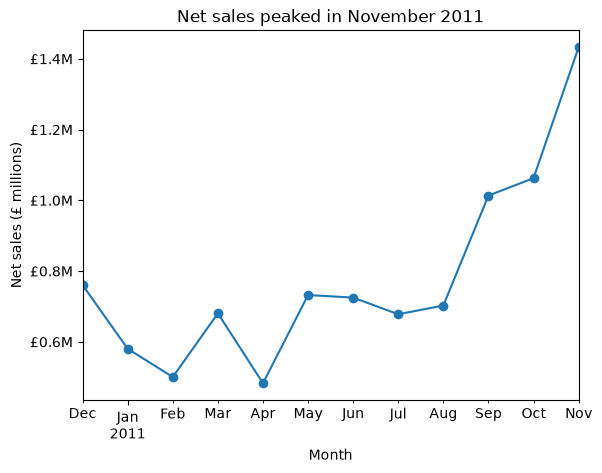

In [79]:
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

os.makedirs('images', exist_ok=True)

full_months = monthly_net.iloc[:-1]

ax = full_months.plot(kind='line', marker='o')
ax.set_title('Net sales peaked in November 2011')
ax.set_xlabel('Month')
ax.set_ylabel('Net sales (£ millions)')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'£{x/1e6:.1f}M'))

plt.savefig('images/monthly_net_sales.png', dpi=150, bbox_inches='tight')
plt.show()

## Monthly Net Sales

November 2011 had the highest net sales (£1,432,734.99), about 35% above October (£1,062,694.33).
Sales rose from September onwards, which is consistent with a pre-Christmas build-up, but one year of data cannot confirm seasonality.
December 2011 is excluded from the chart because the data ends on 9 December.

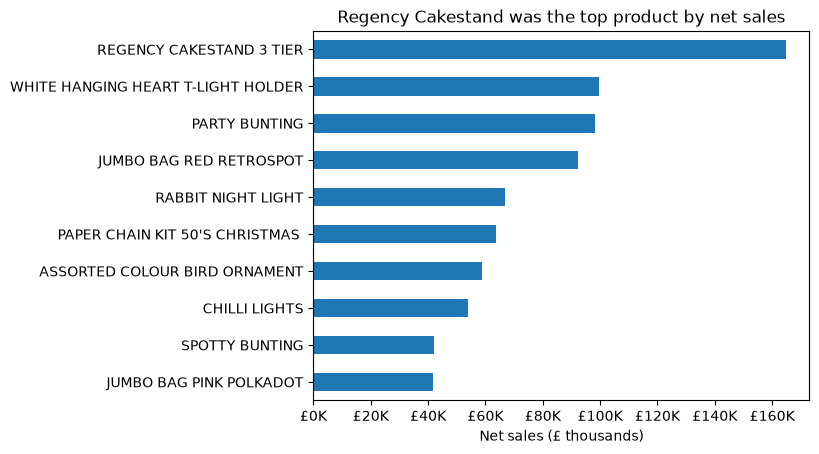

In [80]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

top10 = net_by_product.sort_values()   # smallest first, so the biggest ends up on top

ax = top10.plot(kind='barh')
ax.set_title('Regency Cakestand was the top product by net sales')
ax.set_xlabel('Net sales (£ thousands)')
ax.set_ylabel('')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'£{x/1e3:.0f}K'))

plt.savefig('images/top10_products_net.png', dpi=150, bbox_inches='tight')
plt.show()

In [81]:
country_net = net_sales.groupby('Country')['SalesValue'].sum().sort_values(ascending=False)
country_net.head(10)

Country
United Kingdom    8302406.643
Netherlands        283479.540
EIRE               259663.460
Germany            200808.400
France             182163.390
Australia          136990.000
Switzerland         52505.350
Spain               51765.200
Belgium             36662.960
Japan               35419.790
Name: SalesValue, dtype: float64

In [82]:
total_net = country_net.sum()
uk_share = country_net['United Kingdom'] / total_net * 100
uk_share

np.float64(84.77555272185337)

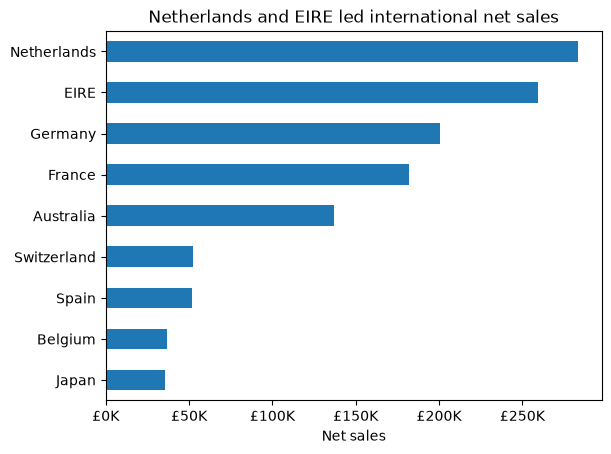

In [83]:
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

os.makedirs('images', exist_ok=True)

top_intl = country_net.drop('United Kingdom').head(9).sort_values()

ax = top_intl.plot(kind='barh')
ax.set_title('Netherlands and EIRE led international net sales')
ax.set_xlabel('Net sales')
ax.set_ylabel('')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'£{x/1e3:.0f}K'))

plt.savefig('images/top_international_countries.png', dpi=150, bbox_inches='tight')
plt.show()

In [84]:
net_sales['CustomerID'].isna().sum()

np.int64(134085)

In [85]:
net_sales['CustomerID'].isna().sum()

np.int64(134085)

In [86]:
with_id = net_sales['CustomerID'].notna()
net_sales[with_id]['SalesValue'].sum() / net_sales['SalesValue'].sum() * 100

np.float64(84.61479829099177)

In [87]:
cust = net_sales[net_sales['CustomerID'].notna()].copy()

In [88]:
len(cust), cust['CustomerID'].nunique()

(404913, 4363)

In [89]:
cust.groupby('CustomerID')['SalesValue'].sum().sort_values(ascending=False).head(10)

CustomerID
14646.0    278778.02
18102.0    259657.30
17450.0    189735.53
14911.0    128882.13
12415.0    123638.18
14156.0    113855.32
17511.0     88138.20
16684.0     65920.12
13694.0     62924.10
15311.0     59419.34
Name: SalesValue, dtype: float64

In [90]:
cust['CustomerID'] = cust['CustomerID'].astype(int)

In [91]:
customer_net = cust.groupby('CustomerID')['SalesValue'].sum().sort_values(ascending=False)
customer_net.head(10).sum() / customer_net.sum() * 100

np.float64(16.544032097875547)

In [92]:
customer_net.head(436).sum() / customer_net.sum() * 100

np.float64(60.22791448697548)

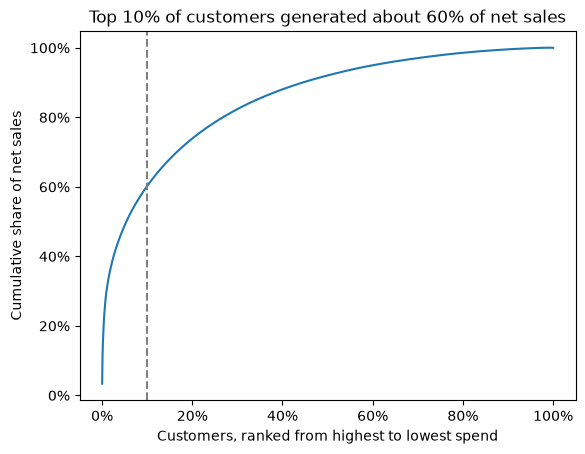

In [93]:
import os
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter

os.makedirs('images', exist_ok=True)

cum_share = customer_net.cumsum() / customer_net.sum() * 100   # running total as a percent
cust_pct = np.arange(1, len(customer_net) + 1) / len(customer_net) * 100   # 1st customer, 2nd... as a percent of all

fig, ax = plt.subplots()
ax.plot(cust_pct, cum_share.values)
ax.set_title('Top 10% of customers generated about 60% of net sales')
ax.set_xlabel('Customers, ranked from highest to lowest spend')
ax.set_ylabel('Cumulative share of net sales')
ax.xaxis.set_major_formatter(PercentFormatter())
ax.yaxis.set_major_formatter(PercentFormatter())
ax.axvline(10, linestyle='--', color='grey')

plt.savefig('images/customer_concentration.png', dpi=150, bbox_inches='tight')
plt.show()

In [94]:
customer_net.head(2182).sum() / customer_net.sum() * 100

np.float64(92.07212691775966)

In [95]:
orders_per_customer = cust.groupby('CustomerID')['InvoiceNo'].nunique()
orders_per_customer.describe()

count    4363.000000
mean        4.993812
std         9.083984
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       242.000000
Name: InvoiceNo, dtype: float64

In [96]:
(orders_per_customer > 1).mean() * 100

np.float64(69.56222782489114)

In [97]:
sales_only = cust[~cust['InvoiceNo'].astype(str).str.startswith('C')]
orders_no_cancel = sales_only.groupby('CustomerID')['InvoiceNo'].nunique()
(orders_no_cancel > 1).mean() * 100

np.float64(65.25951557093425)

In [98]:
len(orders_no_cancel)

4335

## Repeat Purchasing (preliminary)

Customers with an ID placed a median of 3 orders in the period (mean 5.0, maximum 242). About 69.6% placed more than one order. This count includes cancellation invoices, so it is provisional and is rechecked below with cancellations excluded.

In [99]:
snapshot = sales_only['InvoiceDate'].max() + pd.Timedelta(days=1)
snapshot

Timestamp('2011-12-10 12:50:00')

In [100]:
recency = (snapshot - sales_only.groupby('CustomerID')['InvoiceDate'].max()).dt.days
recency.describe()

count    4335.000000
mean       92.684890
std       100.172622
min         1.000000
25%        18.000000
50%        51.000000
75%       143.000000
max       374.000000
Name: InvoiceDate, dtype: float64

In [101]:
customer_net.describe()

count      4363.000000
mean       1899.303993
std        8265.313802
min       -1192.200000
25%         294.205000
50%         645.650000
75%        1594.980000
max      278778.020000
Name: SalesValue, dtype: float64

In [102]:
monetary = sales_only.groupby('CustomerID')['SalesValue'].sum()
monetary.describe()

count      4335.000000
mean       2021.007302
std        8906.526607
min           0.000000
25%         305.410000
50%         668.110000
75%        1631.475000
max      279138.020000
Name: SalesValue, dtype: float64

In [103]:
rfm = pd.DataFrame({'Recency': recency, 'Frequency': orders_no_cancel, 'Monetary': monetary})
rfm.head(2182)

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1437.24
12349,19,1,1457.55
12350,310,1,294.40
...,...,...,...
15311,1,91,60767.90
15312,75,4,924.85
15313,110,1,52.00


In [104]:
(monetary == 0).sum()
monetary[monetary == 0]

CustomerID
13256    0.0
Name: SalesValue, dtype: float64

In [105]:
df[df['CustomerID'] == 13256]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesValue
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.0,13256.0,United Kingdom,0.0


In [106]:
monetary = monetary[monetary > 0]
rfm = pd.DataFrame({'Recency': recency, 'Frequency': orders_no_cancel, 'Monetary': monetary}).dropna()
rfm.shape

(4334, 3)

## Zero-Price Rows

2,515 non-cancellation rows had a unit price of zero. They add £0 to sales value, so they were kept out of the product-sales group. One customer (13256) had only a zero-price row, for 12,540 units, and was excluded from RFM because they made no purchase in the revenue sense. The likely explanation is a stock adjustment, but this is a hypothesis.

In [107]:
rfm.describe()

,Recency,Frequency,Monetary
count,4334.000000,4334.000000,4334.000000
mean,92.703046,4.246424,2021.473616
std,100.177047,7.637059,8907.501378
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,305.560000
50%,51.000000,2.000000,668.125000
75%,143.000000,5.000000,1631.622500
max,374.000000,206.000000,279138.020000


In [108]:
rfm['R'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1])

In [109]:
rfm['R'].value_counts().sort_index()

R
5    881
4    888
3    860
2    838
1    867
Name: count, dtype: int64

In [110]:
rfm['F'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])

In [111]:
rfm['F'].value_counts().sort_index()

F
1    867
2    867
3    866
4    867
5    867
Name: count, dtype: int64

In [112]:
rfm['M'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5])

In [113]:
rfm['M'].value_counts().sort_index()

M
1    867
2    867
3    866
4    867
5    867
Name: count, dtype: int64

In [114]:
rfm['R'] = rfm['R'].astype(int)
rfm['F'] = rfm['F'].astype(int)
rfm['M'] = rfm['M'].astype(int)

In [115]:
def segment(row):
    if row['R'] >= 4 and row['F'] >= 4 and row['M'] >= 4:
        return 'Champions'
    elif row['R'] <= 2 and row['F'] >= 4:
        return 'At risk (were frequent)'
    elif row['R'] >= 4 and row['F'] <= 2:
        return 'Recent / new'
    else:
        return 'Other'

rfm['Segment'] = rfm.apply(segment, axis=1)
rfm['Segment'].value_counts()

Segment
Other                      2784
Champions                   958
Recent / new                319
At risk (were frequent)     273
Name: count, dtype: int64

In [116]:
seg_spend = rfm.groupby('Segment')['Monetary'].sum()
seg_spend / seg_spend.sum() * 100

Segment
At risk (were frequent)     5.311026
Champions                  65.324318
Other                      27.729298
Recent / new                1.635358
Name: Monetary, dtype: float64

## RFM Segments (simple rules)

Customers were scored 1 to 5 on Recency, Frequency and Monetary value, then grouped with simple illustrative rules: Champions (958), Recent / new (319), At risk (273) and Other (2,784).
Monetary here is purchase value excluding returns, ties in Frequency were broken by order of appearance, and customer 13256 was excluded. The rules are a starting point, not a standard.

![International markets](images/top_international_countries.png)
